# Basic Data Analysis

In [2]:
import pandas as pd

# Reading the Excel file
file_name = 'provisionalatmoshpericemissionsghg.xlsx'

# Let's identify the sheets in the file
excel_data = pd.ExcelFile(file_name)
print("Available Sheets in the Dataset:", excel_data.sheet_names)

Available Sheets in the Dataset: ['Table_of_contents', 'Notes', 'GHG total', 'CO2', 'CH4', 'N2O', 'HFC', 'PFC', 'SF6', 'NF3']


In [3]:
# Reading the first 5 rows of the 'GHG total' sheet just to clarify if we are pointing to the right sheet.
df_preview = pd.read_excel(file_name, sheet_name='GHG total', nrows=5)
print("First 5 rows of GHG total sheet:")
df_preview

First 5 rows of GHG total sheet:


,"GHG total: Total greenhouse gas emissions by industry section and group, Mass of air emissions per annum in thousand tonnes of carbon dioxide equivalent, 1990 to 2023 and (provisional) 2024 [note 1]",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 148,Unnamed: 149,Unnamed: 150,Unnamed: 151,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157
0,This worksheet contains two tables. Some cells...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Total figures are based on raw data and theref...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,UK residence basis,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Table 1a: Total greenhouse gas emissions by in...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,R,R,R,R,S,S,S,T,Z,Z


In [4]:
# Reading actual data from the GHG total.
df_actual_data = pd.read_excel(file_name, sheet_name='GHG total', skiprows=6, nrows=5)
print("Data from Row 7 to Row 12:")
df_actual_data

Data from Row 7 to Row 12:


,SIC code,A,B,C,D,E,F,G,H,I,...,91,92,93,94,95,96,97,100,101,Total
0,Industry name,"Agriculture, forestry and fishing",Mining and quarrying,Manufacturing,"Electricity, gas, steam and air conditioning s...","Water supply; sewerage, waste management and r...",Construction,Wholesale and retail trade; repair of motor ve...,Transport and storage,Accommodation and food services,...,"Library, archive, museum and other cultural se...",Gambling and betting services,Sporting services and amusement and recreation...,Services furnished by membership organisations,Repair services of computers and personal and ...,Other personal services,Services of households as employers of domesti...,Consumer expenditure - not travel,Consumer expenditure - travel,Total emission gas emissions
1,1990,56198,50422,172390,217669,73340,7988,11479,67197,3078,...,218,300,1094,548,94,579,101,84323,60896,840542
2,1991,56025,50552,173321,214389,74931,7995,11868,67659,3516,...,224,318,1176,595,95,630,97,93202,60497,850305
3,1992,55677,51134,166467,202593,75029,8117,11680,68660,3230,...,197,287,1077,568,92,606,97,90549,61488,831140
4,1993,54860,50742,162283,185201,75432,8206,11918,69965,3437,...,201,296,1124,612,93,630,98,94863,61954,814579


# Cleaning The Dataset

In [6]:
import numpy as np
import os
import re

os.makedirs('cleaned_outputs', exist_ok=True)

def clean_ons_sheet_final(file_path, sheet_name):
    df_raw = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
    header_mask = df_raw.apply(lambda r: r.astype(str).str.contains('Industry name', case=False).any(), axis=1)
    if not header_mask.any():
        return # Skip if header not found
    header_row_idx = df_raw[header_mask].index[0]
    df = pd.read_excel(file_path, sheet_name=sheet_name, skiprows=header_row_idx)
    df = df.loc[:, ~df.columns.str.contains('^Unnamed', case=False)]
    
    header_cols = [i for i, col in enumerate(df.columns) if 'Industry name' in str(col)]

    if len(header_cols) >= 2:
        df_t1 = df.iloc[:, header_cols[0]:header_cols[1]].dropna(how='all')
        df_t2 = df.iloc[:, header_cols[1]:].dropna(how='all')
    else:
        df_t1 = df.dropna(how='all')
        df_t2 = None

    def process_table(df_target, suffix):
        if df_target is None: return

        df_target = df_target[df_target.iloc[:, 0].notna()] # Drop empty rows
        
        for col in df_target.columns:
            df_target[col] = df_target[col].replace(['[low]', '..', '-', ' ', 'nan', 'NaN'], '0')

            # Convert to numeric
            numeric_check = pd.to_numeric(df_target[col], errors='coerce')
            if not numeric_check.isna().all():
                df_target[col] = numeric_check.fillna(0)

        out_name = f"cleaned_outputs/{sheet_name.replace(' ', '_')}_{suffix}.csv"
        df_target.to_csv(out_name, index=False, float_format='%g')
        print(f"Saving to the file: {out_name}")

    process_table(df_t1, "Industry_Sections")
    process_table(df_t2, "Industry_Groups")

target_sheets = ['GHG total', 'CO2', 'CH4', 'N2O', 'HFC', 'PFC', 'SF6', 'NF3']
for sheet in target_sheets:
    try:
        clean_ons_sheet_final(file_name, sheet)
    except Exception as e:
        print(f"Skipping {sheet} due to: {e}")

Saving to the file: cleaned_outputs/GHG_total_Industry_Sections.csv
Saving to the file: cleaned_outputs/GHG_total_Industry_Groups.csv
Saving to the file: cleaned_outputs/CO2_Industry_Sections.csv
Saving to the file: cleaned_outputs/CO2_Industry_Groups.csv
Saving to the file: cleaned_outputs/CH4_Industry_Sections.csv
Saving to the file: cleaned_outputs/CH4_Industry_Groups.csv
Saving to the file: cleaned_outputs/N2O_Industry_Sections.csv
Saving to the file: cleaned_outputs/N2O_Industry_Groups.csv
Saving to the file: cleaned_outputs/HFC_Industry_Sections.csv
Saving to the file: cleaned_outputs/HFC_Industry_Groups.csv
Saving to the file: cleaned_outputs/PFC_Industry_Sections.csv
Saving to the file: cleaned_outputs/PFC_Industry_Groups.csv
Saving to the file: cleaned_outputs/SF6_Industry_Sections.csv
Saving to the file: cleaned_outputs/SF6_Industry_Groups.csv
Saving to the file: cleaned_outputs/NF3_Industry_Sections.csv
Saving to the file: cleaned_outputs/NF3_Industry_Groups.csv


# Forecast

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


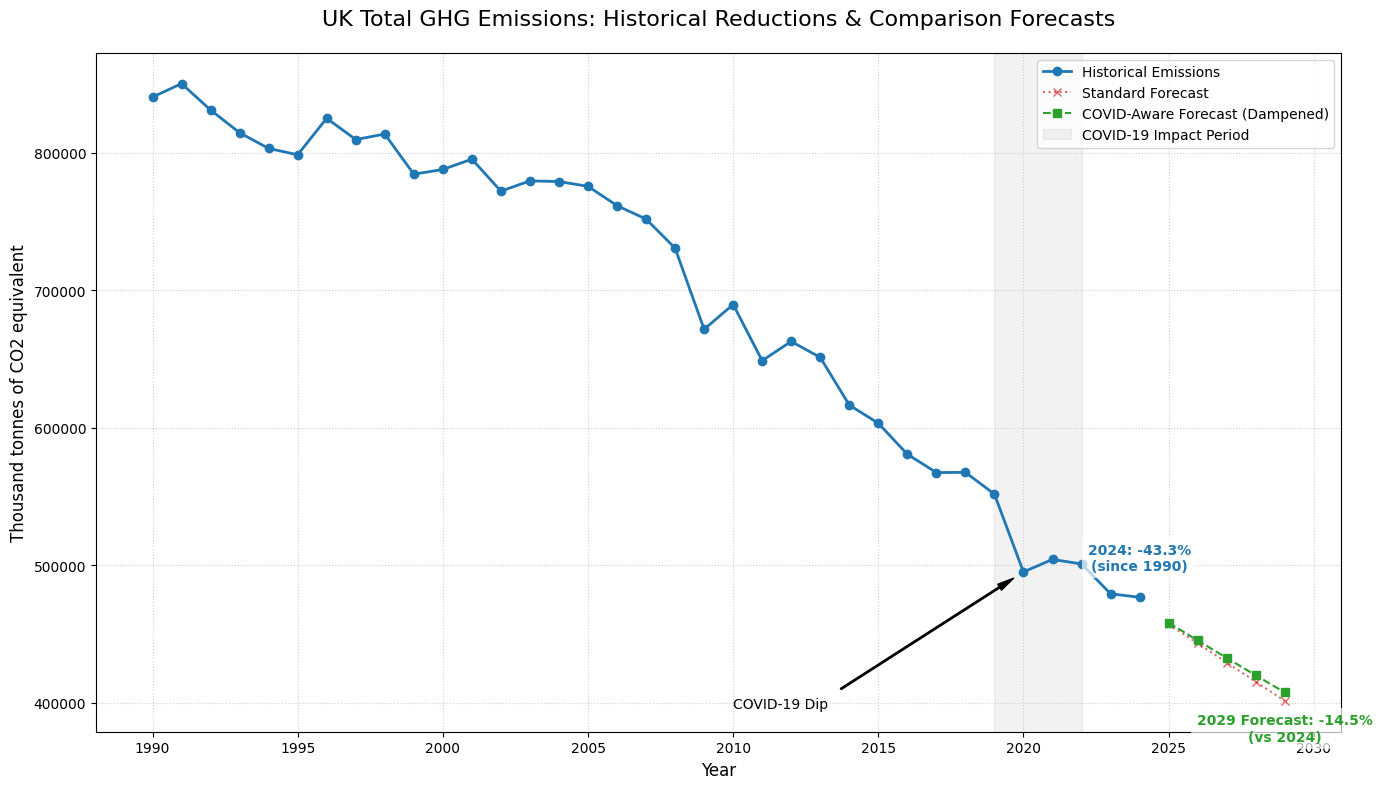

In [8]:
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

#Load the data
df = pd.read_csv('cleaned_outputs/GHG_total_Industry_Sections.csv')

#Column identification
total_col = [c for c in df.columns if 'Total greenhouse gas emissions' in c][0]
year_col = df.columns[0]

ts_data = df[[year_col, total_col]].copy()
ts_data.columns = ['Year', 'Emissions']

#Convert Year to datetime and set as index
ts_data['Year'] = pd.to_datetime(ts_data['Year'].astype(str), format='%Y')
ts_data = ts_data.set_index('Year').sort_index()

#Calculate Historical Percentage Drop (1990 vs 2024)
val_1990 = ts_data.loc['1990-01-01', 'Emissions']
val_2024 = ts_data.loc['2024-01-01', 'Emissions']
hist_drop_perc = ((val_1990 - val_2024) / val_1990) * 100

#Generate Forecasts
forecast_years = 5
# Standard Holt-Winters
model_std = ExponentialSmoothing(ts_data['Emissions'], trend='add', seasonal=None).fit()
forecast_std = model_std.forecast(forecast_years)

# Dampened Holt-Winters (COVID)
model_damp = ExponentialSmoothing(ts_data['Emissions'], trend='add', damped_trend=True, seasonal=None).fit()
forecast_damp = model_damp.forecast(forecast_years)

# Create index for forecast
last_year = ts_data.index[-1]
forecast_index = pd.date_range(start=last_year + pd.DateOffset(years=1), periods=forecast_years, freq='YS')

# 3. Calculate Forecasted Further Drop (2024 vs 2029 COVID)
val_2029_damp = forecast_damp.iloc[-1]
fore_drop_perc = ((val_2024 - val_2029_damp) / val_2024) * 100

#Plotting
plt.figure(figsize=(14, 8))
plt.plot(ts_data.index, ts_data['Emissions'], label='Historical Emissions', marker='o', color='#1f77b4', linewidth=2)

#Forecast Lines
plt.plot(forecast_index, forecast_std, label='Standard Forecast', linestyle=':', marker='x', color='#d62728', alpha=0.7)
plt.plot(forecast_index, forecast_damp, label='COVID-Aware Forecast (Dampened)', linestyle='--', marker='s', color='#2ca02c')

#Highlight COVID period
plt.axvspan(pd.to_datetime('2019'), pd.to_datetime('2022'), color='gray', alpha=0.1, label='COVID-19 Impact Period')

#2024 Historical Drop vs 1990
plt.text(pd.to_datetime('2024'), val_2024 + 20000, 
         f'2024: -{hist_drop_perc:.1f}%\n(since 1990)', 
         color='#1f77b4', fontweight='bold', ha='center', fontsize=10, 
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

#2029 COVID-Aware Drop vs 2024
plt.text(forecast_index[-1], val_2029_damp - 35000, 
         f'2029 Forecast: -{fore_drop_perc:.1f}%\n(vs 2024)', 
         color='#2ca02c', fontweight='bold', ha='center', fontsize=10,
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.title('UK Total GHG Emissions: Historical Reductions & Comparison Forecasts', fontsize=16, pad=20)
plt.ylabel('Thousand tonnes of CO2 equivalent', fontsize=12)
plt.xlabel('Year', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

plt.annotate('COVID-19 Dip', xy=(pd.to_datetime('2020'), ts_data.loc['2020-01-01', 'Emissions']),
             xytext=(pd.to_datetime('2010'), ts_data.loc['2020-01-01', 'Emissions'] * 0.8),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

plt.tight_layout()

output_file = "NAO_GHG_Forecast_Report.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

# More Visualisation and Analysis

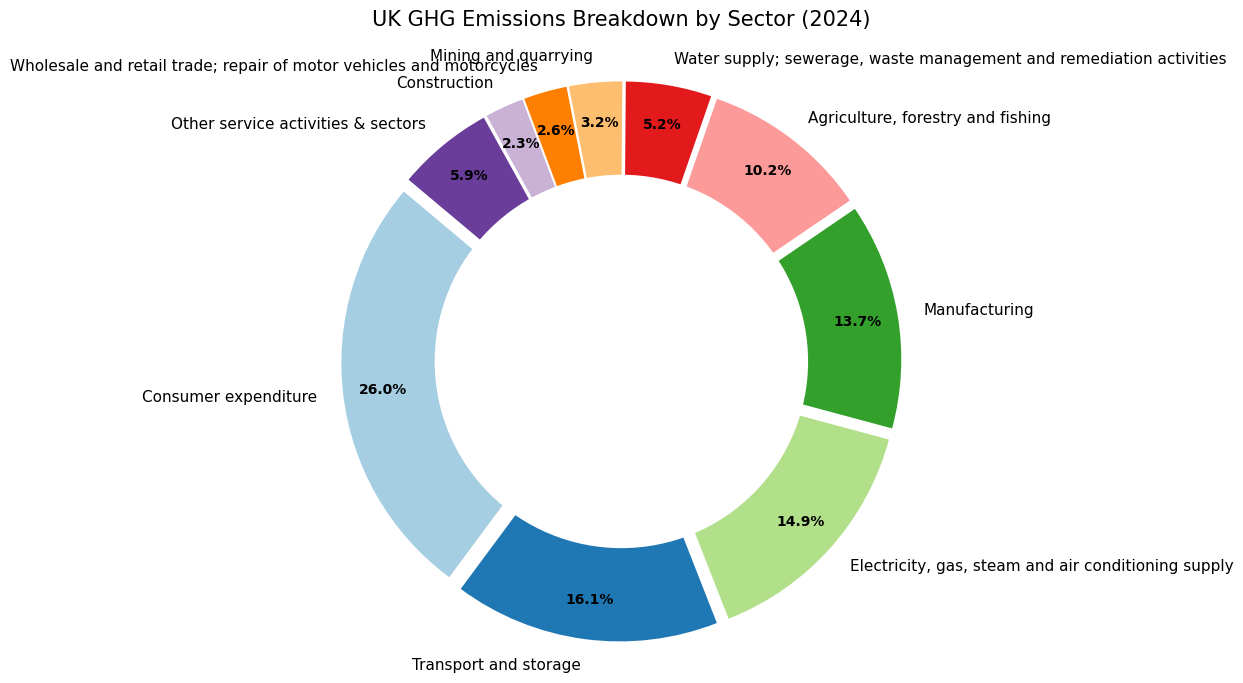

In [10]:
row_2024 = df[df.iloc[:, 0] == 2024]

exclude = [df.columns[0], 'Total greenhouse gas emissions', ' - Not travel', ' - Travel']
# Handling variations in naming
exclude += [c for c in df.columns if 'total' in c.lower() or 'unnamed' in c.lower()]

# Select relevant columns
plot_data = row_2024.drop(columns=[c for c in exclude if c in row_2024.columns])

# Transpose for plotting
plot_series = plot_data.iloc[0].sort_values(ascending=False)

# Grouping small elements into 'Other'
threshold = 0.02 * plot_series.sum()
main_sectors = plot_series[plot_series >= threshold]
other_sectors = plot_series[plot_series < threshold]

if not other_sectors.empty:
    main_sectors['Other service activities & sectors'] = other_sectors.sum()

# Plotting
plt.figure(figsize=(10, 8))
colors = plt.cm.Paired(range(len(main_sectors)))

wedges, texts, autotexts = plt.pie(main_sectors, 
                                  labels=main_sectors.index, 
                                  autopct='%1.1f%%', 
                                  startangle=140, 
                                  colors=colors, 
                                  pctdistance=0.85, 
                                  explode=[0.05]*len(main_sectors))

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('UK GHG Emissions Breakdown by Sector (2024)', fontsize=15, pad=20)
plt.axis('equal')

plt.setp(autotexts, size=10, weight="bold")
plt.setp(texts, size=11)

plt.savefig('sector_breakdown_donut_2024.png', bbox_inches='tight', dpi=300)


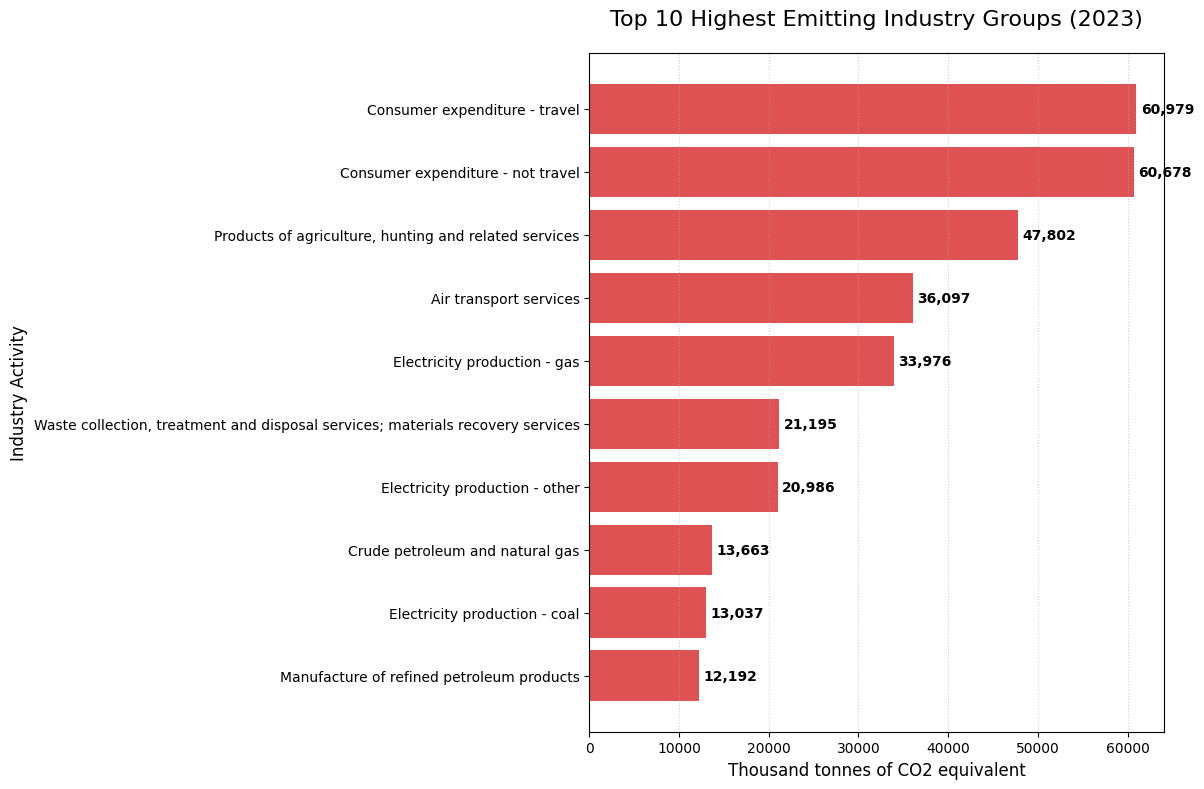

In [11]:
file_path = 'cleaned_outputs/GHG_total_Industry_Groups.csv'
if not os.path.exists(file_path):
    file_path = 'cleaned_outputs/GHG_total_Industry_Groups.csv'

df_groups = pd.read_csv(file_path)

# Identify year and total columns
year_col = df_groups.columns[0]
total_col_options = [c for c in df_groups.columns if 'total' in c.lower() and 'emissions' in c.lower()]
total_col = total_col_options[0] if total_col_options else None

# Find the latest year available in this specific dataset
latest_year = int(df_groups[year_col].max())

row_latest = df_groups[df_groups[year_col] == latest_year]

if row_latest.empty:
    print(f"Error: No data found for year {latest_year}")
else:
    exclude_cols = [year_col] + total_col_options
    data_latest = row_latest.drop(columns=[c for c in exclude_cols if c in row_latest.columns])
    top_10 = data_latest.iloc[0].sort_values(ascending=True).tail(10)

    plt.figure(figsize=(12, 8))
    bars = plt.barh(top_10.index, top_10.values, color='#d62728', alpha=0.8)

    # Add value labels
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 500, bar.get_y() + bar.get_height()/2, 
                 f'{int(width):,}', va='center', fontsize=10, fontweight='bold')

    plt.title(f'Top 10 Highest Emitting Industry Groups ({latest_year})', fontsize=16, pad=20)
    plt.xlabel('Thousand tonnes of CO2 equivalent', fontsize=12)
    plt.ylabel('Industry Activity', fontsize=12)
    plt.grid(axis='x', linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig('top_10_polluters_latest.png', dpi=300)